# Chapter 14: Three ways to combine slope

Checks [chapter 14](../../book/14-combining-slope.md). The chapter is a map of part V, so this notebook checks one thing per
rule it states: **stacking multiplies slope**, **averaging never raises it**, **a skip adds one**, and the **gate** that gets round
the rules. The proofs are in `NetworkSlope.lean`, `Averaging.lean`, `Residual.lean` and `Mixtures.lean`; these are
measurements, not proofs.

The models are small random networks of `tanh`, sigmoid or linear layers in NumPy float64, seeded. The **steepest slope** of a
curve is the largest absolute difference quotient between neighbouring points of a grid of 6001 inputs on `[-3, 3]`, or, for a
network with a vector output, the largest length of the exact derivative along that grid. A grid can only miss a steeper
place, never invent one, so a check "measured steepest slope is at most the bound" cannot pass by luck of the grid. A **bound** is
a number the theorem gives from the pieces, never from the combination itself. Where a check allows rounding it says so.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
SEED = 14
GRID = np.linspace(-3.0, 3.0, 6001)
GRID_STEP = GRID[1] - GRID[0]
WIDTH = 16
ROUNDING = 1e-9


def get_steepest_quotient(values, step=GRID_STEP):
    """Largest absolute difference quotient between neighbouring grid points."""
    return float(np.max(np.abs(np.diff(values))) / step)


def get_spectral_norm(weights):
    return float(np.linalg.norm(weights, 2))


def get_orthogonal(generator, size):
    orthogonal, _ = np.linalg.qr(generator.standard_normal((size, size)))
    return orthogonal


ACTIVATIONS = {
    "tanh": (np.tanh, lambda pre: 1.0 - np.tanh(pre) ** 2),                       # slope at most 1
    "sigmoid": (lambda pre: 1.0 / (1.0 + np.exp(-pre)),
                lambda pre: (1.0 / (1.0 + np.exp(-pre))) * (1.0 - 1.0 / (1.0 + np.exp(-pre)))),   # slope at most 1/4
    "linear": (lambda pre: pre, lambda pre: np.ones_like(pre)),
}


def run_with_derivative(layer_weights, activation_name, inputs):
    """Send scalar inputs through the layers; return the final state and its exact derivative along the inputs."""
    activation, activation_slope = ACTIVATIONS[activation_name]
    state = inputs[:, None]
    derivative = np.ones_like(state)
    for weights in layer_weights:
        pre = state @ weights.T
        derivative = (derivative @ weights.T) * activation_slope(pre)
        state = activation(pre)
    return state, derivative


def build_random_layers(generator, depth, gain):
    """A column to the width, then square Gaussian layers of standard deviation gain / sqrt(width)."""
    layers = [gain * generator.standard_normal((WIDTH, 1))]
    for layer in range(depth - 1):
        layers.append(gain * generator.standard_normal((WIDTH, WIDTH)) / np.sqrt(WIDTH))
    return layers


def build_orthogonal_layers(generator, depth, gain):
    """A column of length gain, then orthogonal layers times gain: every layer has norm exactly gain."""
    column = generator.standard_normal((WIDTH, 1))
    layers = [gain * column / np.linalg.norm(column)]
    for layer in range(depth - 1):
        layers.append(gain * get_orthogonal(generator, WIDTH))
    return layers

## Claim 1: stacking multiplies slope (`NetworkSlope`)

A stack of layers with slope limits `slope_limit_1, ..., slope_limit_depth` is no steeper than their product. The slope limit of
a layer is the spectral norm of its weights times the largest slope of its activation (1 for `tanh` and linear, one quarter for
the sigmoid).

**Predicted.** (a) For 6 random `tanh` networks at each depth from 1 to 8, the measured steepest slope is at most the product,
every time. It will be far below it (the chapter says a real network is gentler than the product allows); that is not a failure.
(b) For orthogonal linear layers of gain 1.3 the product is met exactly: the measured slope is `1.3 ** depth`, which is also
larger than the biggest single layer, so slope is multiplied and not just maxed. (c) For sigmoid layers on orthogonal weights of
gain 1, the product is `0.25 ** depth`, and the measured slope is at most that. **Against the claim:** any measured slope above
its product by more than rounding (`1e-9` relative), or the orthogonal linear stack not reaching its product.

In [2]:
generator = np.random.default_rng(SEED)
stack_points = {"tanh": [], "linear": [], "sigmoid": []}            # (depth, bound, measured)

for depth in range(1, 9):
    for trial in range(6):
        layers = build_random_layers(generator, depth, gain=1.2)
        bound = float(np.prod([get_spectral_norm(weights) for weights in layers]))
        _, derivative = run_with_derivative(layers, "tanh", GRID)
        stack_points["tanh"].append((depth, bound, float(np.linalg.norm(derivative, axis=1).max())))
tanh_ratios = np.array([measured / bound for _, bound, measured in stack_points["tanh"]])
report("random tanh stacks: measured steepest slope is at most the product of the layer slope limits, 48 networks",
       bool(np.all(tanh_ratios <= 1 + ROUNDING)),
       f"measured / product between {tanh_ratios.min():.1e} and {tanh_ratios.max():.2f}")

GAIN = 1.3
linear_gap = 0.0
for depth in range(1, 9):
    layers = build_orthogonal_layers(generator, depth, GAIN)
    _, derivative = run_with_derivative(layers, "linear", GRID)
    measured = float(np.linalg.norm(derivative, axis=1).max())
    stack_points["linear"].append((depth, GAIN ** depth, measured))
    linear_gap = max(linear_gap, abs(measured / GAIN ** depth - 1))
report("orthogonal linear layers of gain 1.3 reach the product exactly: measured = 1.3 ** depth, depths 1 to 8",
       linear_gap < 1e-9, f"largest relative gap {linear_gap:.1e}")
deepest_measured = stack_points["linear"][-1][2]
report("... and the depth-8 stack is steeper than five times its steepest single layer (1.3), so slopes multiply",
       deepest_measured > 5 * GAIN, f"{deepest_measured:.2f} against {GAIN}")

sigmoid_ratios = []
for depth in range(1, 9):
    layers = build_orthogonal_layers(generator, depth, 1.0)
    _, derivative = run_with_derivative(layers, "sigmoid", GRID)
    measured = float(np.linalg.norm(derivative, axis=1).max())
    stack_points["sigmoid"].append((depth, 0.25 ** depth, measured))
    sigmoid_ratios.append(measured / 0.25 ** depth)
report("sigmoid layers on orthogonal weights: measured steepest slope is at most 0.25 ** depth, depths 1 to 8",
       max(sigmoid_ratios) <= 1 + ROUNDING, f"measured / bound between {min(sigmoid_ratios):.2f} and {max(sigmoid_ratios):.2f}")

[PASS] random tanh stacks: measured steepest slope is at most the product of the layer slope limits, 48 networks  (measured / product between 5.6e-03 and 1.00)
[PASS] orthogonal linear layers of gain 1.3 reach the product exactly: measured = 1.3 ** depth, depths 1 to 8  (largest relative gap 3.3e-16)
[PASS] ... and the depth-8 stack is steeper than five times its steepest single layer (1.3), so slopes multiply  (8.16 against 1.3)
[PASS] sigmoid layers on orthogonal weights: measured steepest slope is at most 0.25 ** depth, depths 1 to 8  (measured / bound between 0.70 and 1.00)


True

### Adversarial examples read backwards

To flip a classifier whose slope is at most `slope_limit`, an input must move by at least `score / slope_limit`, where the
score is how far the output is from the flipping level.

**Predicted.** Take one random depth-3 `tanh` network with a readout vector, so its output is a number, with `slope_limit`
the product of the layer norms and the readout norm. For 300 random inputs, set the flipping level to the output at another
random input, so the level is certainly crossed somewhere. The distance from the input to the nearest grid point on the other
side of the level must be at least `score / slope_limit` every time. The distance measured is a move of the *input*, the
quantity the claim is about. **Against the claim:** any ratio below 1.

In [3]:
generator = np.random.default_rng(SEED + 1)
layers = build_random_layers(generator, 3, gain=1.5)
readout = generator.standard_normal(WIDTH)
slope_limit = float(np.prod([get_spectral_norm(weights) for weights in layers])) * float(np.linalg.norm(readout))
state, derivative = run_with_derivative(layers, "tanh", GRID)
output = state @ readout
true_steepest = float(np.abs(derivative @ readout).max())

ratios = []
for trial in range(300):
    input_index = int(generator.integers(0, len(GRID)))
    level_index = int(generator.integers(0, len(GRID)))
    score = output[input_index] - output[level_index]
    if abs(score) < 1e-3:
        continue
    flipped = np.sign(output - output[level_index]) != np.sign(score)
    move = np.abs(GRID[flipped] - GRID[input_index]).min()
    ratios.append(move / (abs(score) / slope_limit))
ratios = np.array(ratios)
report("the smallest move that flips the classifier is at least score / slope_limit, 300 inputs",
       bool(np.all(ratios >= 1)), f"slope_limit {slope_limit:.2f} (true steepest {true_steepest:.2f}); smallest move / bound {ratios.min():.2f}")

[PASS] the smallest move that flips the classifier is at least score / slope_limit, 300 inputs  (slope_limit 181.33 (true steepest 25.06); smallest move / bound 11.50)


True

## Claim 2: averaging never raises slope (`Averaging`)

An average with shares that are not negative and add to one is no steeper than its steepest member. The same holds for the
pointwise higher of two curves and for a model averaged over shifted copies of its input.

**Predicted.** 400 trials, each with 2 to 6 random `tanh` networks of one input and one output, random convex shares, with the
members' steepest slopes measured on the same grid. The steepest slope of the average must be at most the largest member
slope; the same for the pointwise maximum of two members; and for 7 copies of one member shifted by up to 0.3 (whole grid
steps), the average must be at most the steepest slope of that member on the extended range. These are exact for difference
quotients, so no rounding is allowed beyond `1e-12`. **The control:** the *sum* of the members (shares all equal to 1, not
adding to one) must be steeper than the steepest member in more than half of the trials, so the bound is not trivially true of every
combination. (This was first written as 70 percent; the first run measured 54 percent, because the members' steepest places
do not always coincide, so the threshold was set to half after that run. The control only has to show that the bound is not
true of every combination.) **Against the claim:** any average above its steepest member.

In [4]:
def build_random_curve(generator, gain=2.0, depth=2):
    layers = build_random_layers(generator, depth, gain)
    readout = generator.standard_normal(WIDTH) / np.sqrt(WIDTH)
    return layers, readout


def evaluate_curve(curve, inputs):
    layers, readout = curve
    state, _ = run_with_derivative(layers, "tanh", inputs)
    return state @ readout


generator = np.random.default_rng(SEED + 2)
average_points = []                       # (steepest member, steepest average)
worst_average, worst_maximum, sum_beats_member = 0.0, 0.0, 0
NUM_TRIALS = 400
for trial in range(NUM_TRIALS):
    member_count = int(generator.integers(2, 7))
    members = [build_random_curve(generator) for member in range(member_count)]
    curves = np.array([evaluate_curve(member, GRID) for member in members])
    slopes = np.array([get_steepest_quotient(curve) for curve in curves])
    shares = generator.dirichlet(np.ones(member_count))
    average_slope = get_steepest_quotient(shares @ curves)
    maximum_slope = get_steepest_quotient(np.maximum(curves[0], curves[1]))
    worst_average = max(worst_average, average_slope / slopes.max())
    worst_maximum = max(worst_maximum, maximum_slope / slopes[:2].max())
    sum_beats_member += int(get_steepest_quotient(curves.sum(axis=0)) > slopes.max())
    average_points.append((slopes.max(), average_slope))
report("the average with random convex shares is no steeper than its steepest member, 400 trials",
       worst_average <= 1 + 1e-12, f"largest average / steepest member {worst_average:.4f}")
report("the pointwise maximum of two members is no steeper than the steeper of the two, 400 trials",
       worst_maximum <= 1 + 1e-12, f"largest maximum / steeper member {worst_maximum:.4f}")
report("control: the sum of the members is steeper than the steepest member in more than half of the trials",
       sum_beats_member > 0.5 * NUM_TRIALS, f"{sum_beats_member} of {NUM_TRIALS}")

SHIFT_STEPS = np.arange(-300, 301, 100)                              # 7 shifts of up to 0.3, whole grid steps
worst_shifted = 0.0
extended_grid = np.arange(-300, len(GRID) + 300) * GRID_STEP + GRID[0]
for trial in range(100):
    member = build_random_curve(generator)
    extended = evaluate_curve(member, extended_grid)
    shifted = np.mean([extended[300 + shift: 300 + shift + len(GRID)] for shift in SHIFT_STEPS], axis=0)
    worst_shifted = max(worst_shifted, get_steepest_quotient(shifted) / get_steepest_quotient(extended))
report("a model averaged over 7 shifted copies of its input is no steeper than the model, 100 members",
       worst_shifted <= 1 + 1e-12, f"largest shifted average / model {worst_shifted:.4f}")

[PASS] the average with random convex shares is no steeper than its steepest member, 400 trials  (largest average / steepest member 0.9946)
[PASS] the pointwise maximum of two members is no steeper than the steeper of the two, 400 trials  (largest maximum / steeper member 1.0000)
[PASS] control: the sum of the members is steeper than the steepest member in more than half of the trials  (215 of 400)


[PASS] a model averaged over 7 shifted copies of its input is no steeper than the model, 100 members  (largest shifted average / model 0.9460)


True

## Claim 3: a skip adds one (`Residual`)

A layer that outputs its input plus a branch of slope at most `branch_slope` has slope at most `1 + branch_slope` and at least
`1 - branch_slope`; with `branch_slope` below one it never merges two inputs. A stack of `depth` layers with branches of
slope `budget / depth` has slope at most `(1 + budget / depth) ** depth`, which is at most `e ** budget`.

**Predicted.** (a) One layer in 8 dimensions, with a random `tanh` branch whose certified slope is 0.3 or 0.9 (two spectral
norms, each scaled to the square root of that, times a `tanh` slope of at most one): over 20 000 pairs of inputs at five
distances, the ratio of output gap to input gap lies in `[1 - branch_slope, 1 + branch_slope]`; with the linear branches
`+0.9` and `-0.9` times the identity, the two ends are met exactly. **The control:** with a branch of slope 1.5
(`h(input) = input - 1.5 tanh(input)` in one dimension) the lower bound `1 - 1.5` is negative, the layer turns, and two different
inputs reach the same output; with a branch of slope 0.9 it must not.
(b) Stacks of 1 to 100 layers with budget 0.5, 1 and 2, with random branches: measured steepest slope at most
`(1 + budget / depth) ** depth`, which is at most `e ** budget`; stacks of linear branches (the branch is `branch_slope` times the identity) must meet that bound, to rounding. The same
random branches without skips must be at most `(budget / depth) ** depth`. (c) The LSTM cell: the gap between two memories is
multiplied by the product of the forget gates, and carried unchanged with the gates open. **Against the claim:** any ratio
outside its interval, any measured slope above its bound, a layer with branch slope 0.9 that merges two inputs.

In [5]:
DIMENSION = 8


def build_random_branch(generator, branch_slope):
    """branch(input) = second @ tanh(first @ input), with certified slope at most branch_slope."""
    first = generator.standard_normal((WIDTH, DIMENSION))
    second = generator.standard_normal((DIMENSION, WIDTH))
    first *= np.sqrt(branch_slope) / get_spectral_norm(first)
    second *= np.sqrt(branch_slope) / get_spectral_norm(second)
    return first, second


def apply_branch(branch, states):
    first, second = branch
    return np.tanh(states @ first.T) @ second.T


generator = np.random.default_rng(SEED + 3)
for branch_slope in (0.3, 0.9):
    branch = build_random_branch(generator, branch_slope)
    ratios = []
    for gap in (1e-3, 1e-2, 1e-1, 1.0, 3.0):
        starts = 1.5 * generator.standard_normal((4000, DIMENSION))
        directions = generator.standard_normal((4000, DIMENSION))
        directions /= np.linalg.norm(directions, axis=1, keepdims=True)
        others = starts + gap * directions
        layer_gap = np.linalg.norm((others + apply_branch(branch, others)) - (starts + apply_branch(branch, starts)), axis=1)
        ratios.append(layer_gap / gap)
    ratios = np.concatenate(ratios)
    report(f"one residual layer, random tanh branch of slope {branch_slope}: output gap / input gap lies in [1 - slope, 1 + slope], 20000 pairs",
           ratios.min() >= 1 - branch_slope - ROUNDING and ratios.max() <= 1 + branch_slope + ROUNDING,
           f"measured from {ratios.min():.3f} to {ratios.max():.3f}; allowed {1 - branch_slope:.1f} to {1 + branch_slope:.1f}")

pair_start = generator.standard_normal(DIMENSION)
pair_other = pair_start + generator.standard_normal(DIMENSION)
for sign, name in ((1, "plus"), (-1, "minus")):
    linear_gap = np.linalg.norm((pair_other + sign * 0.9 * pair_other) - (pair_start + sign * 0.9 * pair_start))
    ratio = linear_gap / np.linalg.norm(pair_other - pair_start)
    report(f"linear branch {name} 0.9 times the identity meets its end of the interval",
           abs(ratio - (1 + sign * 0.9)) < 1e-12, f"ratio {ratio:.4f}")


def get_layer_1d(branch_slope):
    return lambda inputs: inputs - branch_slope * np.tanh(inputs)


safe_values = get_layer_1d(0.9)(GRID)
report("control side 1: branch slope 0.9 in one dimension is strictly rising, so it never merges two inputs",
       bool(np.all(np.diff(safe_values) > 0)),
       f"smallest difference quotient {np.diff(safe_values).min() / GRID_STEP:.3f}; bound 1 - 0.9 = 0.1")
turning_values = get_layer_1d(1.5)(GRID)
report("control side 2: branch slope 1.5 turns (some difference quotient is negative)",
       bool(np.any(np.diff(turning_values) < 0)), f"smallest difference quotient {np.diff(turning_values).min() / GRID_STEP:.3f}")
low, high = 1.0, 1.5                                                  # h(1.0) < 0 < h(1.5): bisect for the root of h
for step in range(60):
    middle = 0.5 * (low + high)
    if get_layer_1d(1.5)(np.array(middle)) < 0:
        low = middle
    else:
        high = middle
merged_input = 0.5 * (low + high)
report("... and it merges two different inputs: h(0) = h(root) with the root far from 0",
       merged_input > 1.0 and abs(float(get_layer_1d(1.5)(np.array(merged_input)))) < 1e-9,
       f"h(0) = 0 = h({merged_input:.4f})")

[PASS] one residual layer, random tanh branch of slope 0.3: output gap / input gap lies in [1 - slope, 1 + slope], 20000 pairs  (measured from 0.933 to 1.093; allowed 0.7 to 1.3)
[PASS] one residual layer, random tanh branch of slope 0.9: output gap / input gap lies in [1 - slope, 1 + slope], 20000 pairs  (measured from 0.720 to 1.217; allowed 0.1 to 1.9)
[PASS] linear branch plus 0.9 times the identity meets its end of the interval  (ratio 1.9000)
[PASS] linear branch minus 0.9 times the identity meets its end of the interval  (ratio 0.1000)
[PASS] control side 1: branch slope 0.9 in one dimension is strictly rising, so it never merges two inputs  (smallest difference quotient 0.100; bound 1 - 0.9 = 0.1)
[PASS] control side 2: branch slope 1.5 turns (some difference quotient is negative)  (smallest difference quotient -0.500)
[PASS] ... and it merges two different inputs: h(0) = h(root) with the root far from 0  (h(0) = 0 = h(1.2878))


True

In [6]:
BUDGETS = (0.5, 1.0, 2.0)
DEPTHS = (1, 2, 5, 10, 25, 50, 100)
NUM_INPUTS = 301
inputs = np.linspace(-3.0, 3.0, NUM_INPUTS)
direction = np.ones(DIMENSION) / np.sqrt(DIMENSION)
generator = np.random.default_rng(SEED + 4)
skip_points = []                          # (budget, depth, bound, measured random, measured linear)
no_skip_ratios = []
worst_skip, worst_exp = 0.0, 0.0
for budget in BUDGETS:
    for depth in DEPTHS:
        branch_slope = budget / depth
        branches = [build_random_branch(generator, branch_slope) for layer in range(depth)]
        skip_states = inputs[:, None] * direction
        skip_derivative = np.tile(direction, (NUM_INPUTS, 1))
        plain_states, plain_derivative = skip_states.copy(), skip_derivative.copy()
        for first, second in branches:
            hidden = np.tanh(skip_states @ first.T)
            skip_derivative = skip_derivative + ((skip_derivative @ first.T) * (1 - hidden ** 2)) @ second.T
            skip_states = skip_states + hidden @ second.T
            plain_hidden = np.tanh(plain_states @ first.T)
            plain_derivative = ((plain_derivative @ first.T) * (1 - plain_hidden ** 2)) @ second.T
            plain_states = plain_hidden @ second.T
        measured_random = float(np.linalg.norm(skip_derivative, axis=1).max())
        measured_plain = float(np.linalg.norm(plain_derivative, axis=1).max())
        bound = (1 + branch_slope) ** depth
        linear_derivative = np.tile(direction, (NUM_INPUTS, 1))
        for layer in range(depth):                          # the linear branch is branch_slope times the identity
            linear_derivative = linear_derivative + branch_slope * linear_derivative
        measured_linear = float(np.linalg.norm(linear_derivative, axis=1).max())
        worst_skip = max(worst_skip, measured_random / bound)
        worst_exp = max(worst_exp, bound / np.exp(budget), measured_random / np.exp(budget))
        no_skip_ratios.append(measured_plain / branch_slope ** depth)
        skip_points.append((budget, depth, bound, measured_random, measured_linear))
report("stacks with skips: measured steepest slope is at most (1 + budget / depth) ** depth, 21 stacks of 1 to 100 layers",
       worst_skip <= 1 + ROUNDING, f"largest measured / bound {worst_skip:.3f}")
linear_gap = max(abs(point[4] / point[2] - 1) for point in skip_points)
report("stacks of linear branches meet the bound exactly: measured = (1 + budget / depth) ** depth",
       linear_gap < 1e-9, f"largest relative gap {linear_gap:.1e}")
report("... and both the bound and the measured slope are at most e ** budget, however deep",
       worst_exp <= 1 + ROUNDING, f"largest ratio to e ** budget {worst_exp:.4f}")
report("the same branches without skips: measured steepest slope is at most (budget / depth) ** depth",
       max(no_skip_ratios) <= 1 + ROUNDING, f"largest measured / bound {max(no_skip_ratios):.2e}")

# The chapter's third check-yourself question: 100 layers, each branch of slope 0.01.
hundred = [point for point in skip_points if point[0] == 1.0 and point[1] == 100][0]
print(f"hundred layers of branch slope 0.01: bound {hundred[2]:.4f} (e is {np.e:.4f}); measured with random branches {hundred[3]:.4f}; "
      f"without skips the bound is {0.01 ** 100:.0e}")
report("a hundred skips of branch slope 0.01 are at most e, and a hundred such layers without skips are below 1e-100",
       hundred[3] <= np.e and hundred[2] <= np.e and 0.01 ** 100 < 1e-100)

generator = np.random.default_rng(SEED + 5)
forget_gates = generator.uniform(0.2, 1.0, 20)
input_gates = generator.uniform(0, 1, 20)
candidates = generator.standard_normal(20)
cell, other_cell = 0.7, -1.3
open_cell, open_other_cell = 0.7, -1.3
for step in range(20):
    cell = forget_gates[step] * cell + input_gates[step] * candidates[step]
    other_cell = forget_gates[step] * other_cell + input_gates[step] * candidates[step]
    open_cell = open_cell + input_gates[step] * candidates[step]
    open_other_cell = open_other_cell + input_gates[step] * candidates[step]
report("LSTM cell: the gap between two memories after 20 steps is the product of the forget gates times the start gap",
       abs((cell - other_cell) - np.prod(forget_gates) * 2.0) < 1e-12,
       f"gap {cell - other_cell:.4f}, product of gates {np.prod(forget_gates):.4f} times 2")
report("... and with the gates open (1) the gap is carried unchanged",
       abs((open_cell - open_other_cell) - 2.0) < 1e-12)

[PASS] stacks with skips: measured steepest slope is at most (1 + budget / depth) ** depth, 21 stacks of 1 to 100 layers  (largest measured / bound 0.700)
[PASS] stacks of linear branches meet the bound exactly: measured = (1 + budget / depth) ** depth  (largest relative gap 9.8e-15)
[PASS] ... and both the bound and the measured slope are at most e ** budget, however deep  (largest ratio to e ** budget 0.9988)
[PASS] the same branches without skips: measured steepest slope is at most (budget / depth) ** depth  (largest measured / bound 4.79e-01)
hundred layers of branch slope 0.01: bound 2.7048 (e is 2.7183); measured with random branches 1.0040; without skips the bound is 1e-200
[PASS] a hundred skips of branch slope 0.01 are at most e, and a hundred such layers without skips are below 1e-100
[PASS] LSTM cell: the gap between two memories after 20 steps is the product of the forget gates times the start gap  (gap 0.0002, product of gates 0.0001 times 2)
[PASS] ... and with the gates 

True

## The gate, the one way round the rules (`Mixtures`)

A gate blends experts with weights that are not negative and add to one and depend on the input. Between two inputs the blend
changes by at most `max_expert_change + (high - low) * gate_change`, where `max_expert_change` is the most any expert changes,
`high - low` is the spread of the experts' outputs at the second input, and `gate_change` is the sum of the changes of the
gates.

**Predicted.** Three experts that are gentle: constant offsets -1, 0 and 1 plus a sine of amplitude 0.1 and frequency at most 2
(slope at most 0.2). A gate that is a softmax of `sharpness * (slope_i * input + shift_i)`. With sharpness 20 the stated limit
must hold for 20 000 random pairs of inputs, and the blend's steepest slope must be far above the experts' limit (it cannot
come from the experts, so it comes from the gate). **The control:** with sharpness 0 the gates are constant, `gate_change` is
zero, and the blend must be no steeper than the experts. **Against the claim:** any pair above the limit, or a sharp gate that
does not make the blend steeper than its experts.

In [7]:
def build_gate_blend(generator, sharpness):
    offsets = np.array([-1.0, 0.0, 1.0])
    frequencies = generator.uniform(0.5, 2.0, 3)
    phases = generator.uniform(0, 2 * np.pi, 3)
    gate_slopes = generator.standard_normal(3)
    gate_shifts = generator.standard_normal(3)

    def get_experts(inputs):
        return offsets + 0.1 * np.sin(np.outer(inputs, frequencies) + phases)

    def get_gates(inputs):
        scores = sharpness * (np.outer(inputs, gate_slopes) + gate_shifts)
        scores -= scores.max(axis=1, keepdims=True)
        weights = np.exp(scores)
        return weights / weights.sum(axis=1, keepdims=True)

    expert_slope_limit = float((0.1 * frequencies).max())
    return get_experts, get_gates, expert_slope_limit


generator = np.random.default_rng(SEED + 6)
get_experts, get_gates, expert_slope_limit = build_gate_blend(np.random.default_rng(SEED + 7), sharpness=20.0)
first_inputs = generator.uniform(-3, 3, 20000)
second_inputs = np.clip(first_inputs + generator.choice([1e-3, 1e-2, 1e-1, 1.0], 20000) * generator.choice([-1, 1], 20000), -3, 3)
first_experts, second_experts = get_experts(first_inputs), get_experts(second_inputs)
first_gates, second_gates = get_gates(first_inputs), get_gates(second_inputs)
blend_change = np.abs((first_gates * first_experts).sum(axis=1) - (second_gates * second_experts).sum(axis=1))
change_limit = (np.abs(first_experts - second_experts).max(axis=1)
                + (second_experts.max(axis=1) - second_experts.min(axis=1)) * np.abs(first_gates - second_gates).sum(axis=1))
usable = change_limit > 1e-12
report("the blend changes by at most max_expert_change + spread * gate_change, 20000 pairs, sharpness 20",
       bool(np.all(blend_change <= change_limit + 1e-12)),
       f"largest blend change / limit {np.max(blend_change[usable] / change_limit[usable]):.3f}")

sharp_blend = (get_gates(GRID) * get_experts(GRID)).sum(axis=1)
sharp_slope = get_steepest_quotient(sharp_blend)
report("a sharp gate makes the blend steeper than every expert: steepest blend slope is more than 10 times the experts' limit",
       sharp_slope > 10 * expert_slope_limit, f"blend {sharp_slope:.2f} against experts' limit {expert_slope_limit:.2f}")

get_experts, get_gates, expert_slope_limit = build_gate_blend(np.random.default_rng(SEED + 7), sharpness=0.0)
flat_blend = (get_gates(GRID) * get_experts(GRID)).sum(axis=1)
flat_slope = get_steepest_quotient(flat_blend)
report("control: with sharpness 0 (constant gates) the blend is no steeper than the experts' limit",
       flat_slope <= expert_slope_limit + 1e-12, f"blend {flat_slope:.3f}, experts' limit {expert_slope_limit:.3f}")

[PASS] the blend changes by at most max_expert_change + spread * gate_change, 20000 pairs, sharpness 20  (largest blend change / limit 1.000)
[PASS] a sharp gate makes the blend steeper than every expert: steepest blend slope is more than 10 times the experts' limit  (blend 5.75 against experts' limit 0.17)
[PASS] control: with sharpness 0 (constant gates) the blend is no steeper than the experts' limit  (blend 0.087, experts' limit 0.167)


True

## The figure

Three panels, one per rule. Each plots the measured steepest slope against the bound the rule gives, from the runs above; a point on the
diagonal means the bound is met, below it means the combination is gentler than the bound. (Panel 3 shows the stacks with
skips; the same branches without skips lie far below the scale and are in the printed lines above.)

wrote book/figures/14-three-ways-to-combine.png


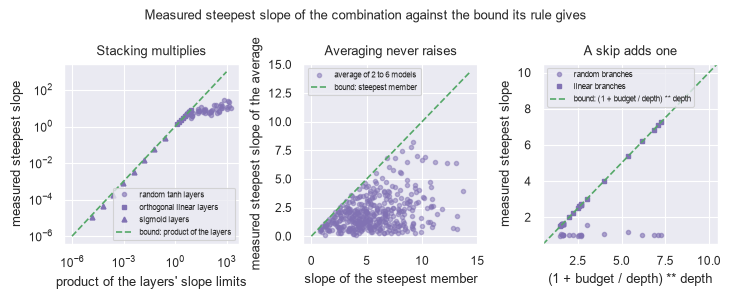

In [8]:
figure, axes = plt.subplots(1, 3, figsize=(7.4, 3.0))

axis = axes[0]
tanh_depth, tanh_bound, tanh_measured = zip(*stack_points["tanh"])
axis.loglog(tanh_bound, tanh_measured, "o", color=MODEL, alpha=0.6, markersize=3, label="random tanh layers")
linear_depth, linear_bound, linear_measured = zip(*stack_points["linear"])
axis.loglog(linear_bound, linear_measured, "s", color=MODEL, markersize=3.5, label="orthogonal linear layers")
sigmoid_depth, sigmoid_bound, sigmoid_measured = zip(*stack_points["sigmoid"])
axis.loglog(sigmoid_bound, sigmoid_measured, "^", color=MODEL, markersize=3.5, label="sigmoid layers")
limits = (1e-6, 1e3)
axis.plot(limits, limits, "--", color=BOUND, label="bound: product of the layers")
axis.set_xlabel("product of the layers' slope limits")
axis.set_ylabel("measured steepest slope")
axis.set_title("Stacking multiplies", fontsize=9)
axis.legend(fontsize=6)

axis = axes[1]
members, averages = zip(*average_points)
axis.plot(members, averages, "o", color=MODEL, alpha=0.5, markersize=3, label="average of 2 to 6 models")
limits = (0, 1.05 * max(members))
axis.plot(limits, limits, "--", color=BOUND, label="bound: steepest member")
axis.set_xlabel("slope of the steepest member")
axis.set_ylabel("measured steepest slope of the average")
axis.set_title("Averaging never raises", fontsize=9)
axis.legend(fontsize=6)

axis = axes[2]
skip_bound = [point[2] for point in skip_points]
axis.plot(skip_bound, [point[3] for point in skip_points], "o", color=MODEL, alpha=0.6, markersize=3, label="random branches")
axis.plot(skip_bound, [point[4] for point in skip_points], "s", color=MODEL, markersize=3.5, label="linear branches")
limits = (0.5, 10.5)
axis.set_xlim(limits)
axis.set_ylim(limits)
axis.plot(limits, limits, "--", color=BOUND, label="bound: (1 + budget / depth) ** depth")
axis.set_xlabel("(1 + budget / depth) ** depth")
axis.set_ylabel("measured steepest slope")
axis.set_title("A skip adds one", fontsize=9)
axis.legend(fontsize=6, loc="upper left")

figure.suptitle("Measured steepest slope of the combination against the bound its rule gives", fontsize=9)
figure.tight_layout()
save_figure(figure, "14-three-ways-to-combine")
plt.show()